# Módulo 11 — O modelo BCC97: volatilidade estocástica, saltos e juros estocásticos

## Introdução

O modelo de **Bakshi, Cao e Chen (1997)**, o BCC97, é o modelo geral deste livro. Ele reúne três mecanismos, cada um ligado a um stylized fact do Capítulo 2: **volatilidade estocástica** à maneira de Heston, que produz agrupamento de volatilidade e, com correlação negativa entre preço e variância, o skew; **saltos** à maneira de Merton, que explicam o skew acentuado dos prazos curtos; e **juros estocásticos** à maneira de Cox, Ingersoll e Ross, relevantes para opções longas.

Apesar da riqueza, o modelo continua tratável. Os três blocos são processos **afins**, e para essa classe a função característica do log-preço tem forma fechada. Assim, as opções europeias podem ser precificadas pelos métodos de Fourier dos Capítulos 7 e 8.

O capítulo apresenta o modelo bloco a bloco, a dinâmica de cada fator e o seu efeito sobre o smile, deduz o preço de títulos no modelo CIR e monta a função característica completa.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 9 do livro.

## O que você vai conseguir fazer ao final

1. Escrever o modelo de Bakshi, Cao e Chen (1997) e reconhecer seus casos particulares.
2. Deduzir o preço do título zero-cupom no CIR, resolvendo uma equação de Riccati.
3. Deduzir a função característica de Heston pelo mesmo caminho.
4. Evitar a armadilha numérica da fórmula original de Heston.
5. Deduzir a EDP do modelo e conferi-la numericamente.
6. Medir o que a aproximação do livro para os juros estocásticos deixa de fora.
7. Saber o que cada parâmetro faz com a superfície de volatilidade.

## Onde estamos

O Módulo 2 mostrou, em mundos sintéticos, que cada stylized fact pede um mecanismo: volatilidade estocástica para o agrupamento e a curvatura, correlação negativa para o skew, saltos para o skew dos prazos curtos, e juros com reversão à média. O Módulo 10 mostrou que Merton sozinho não ajusta vários prazos. O BCC97 junta tudo.

A ferramenta que dá unidade ao módulo é a **estrutura afim**: nos três componentes, a função característica tem a forma $\exp(A + B\cdot\text{estado})$, e encontrar $A$ e $B$ se reduz a resolver equações diferenciais ordinárias.

## 0. Preparação

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson, solve_ivp
from scipy.optimize import brentq
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-12 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. O modelo

**Livro: §9.2 e §9.3**

Sob $Q$, as três equações são:

$$\frac{dS_t}{S_{t-}} = (r_t - r_J)\,dt + \sqrt{v_t}\,dZ^1_t + (e^J - 1)\,dN_t \qquad\text{(índice: Bates, 1996)}$$

$$dv_t = \kappa_v(\theta_v - v_t)\,dt + \sigma_v\sqrt{v_t}\,dZ^2_t \qquad\text{(variância: Heston, 1993)}$$

$$dr_t = \kappa_r(\theta_r - r_t)\,dt + \sigma_r\sqrt{r_t}\,dZ^3_t \qquad\text{(juros: CIR, 1985)}$$

com $dZ^1dZ^2 = \rho\,dt$, e o terceiro browniano e os saltos independentes do resto. Os saltos são como no Módulo 10, com $J \sim N(\mu_J, \delta^2)$ e $r_J = \lambda(e^{\mu_J + \delta^2/2} - 1)$.

> **Errata repetida do capítulo 8.** A lei $\ln(1+J) \sim N(\ln(1+\mu_J) - \delta^2/2, \delta^2)$ escrita na §9.2 não é a que corresponde a $r_J$ e à função característica (9.11). A lei correta é $J \sim N(\mu_J, \delta^2)$, para o log-salto.

### 1.1 Casos particulares

| Modelo | Liga | Desliga |
|---|---|---|
| BSM | — | $\sigma_v = 0$, $\lambda = 0$, juros constantes |
| Merton (M76) | saltos | $\sigma_v = 0$ |
| Heston (H93) | volatilidade estocástica | $\lambda = 0$ |
| Bates (B96) | volatilidade estocástica e saltos | juros estocásticos |
| CIR (CIR85) | juros | — |

São 3 parâmetros de juros e 9 de ações: $v_0, \kappa_v, \theta_v, \sigma_v, \rho, \lambda, \mu_J, \delta$, além de $S_0$ observado.

### 1.2 Um papel para cada componente

Os próprios autores resumem seus resultados empíricos assim (§9.3): a volatilidade estocástica é a melhoria de primeira ordem sobre o BSM; os saltos ajudam nos prazos curtos; os juros estocásticos, nos longos. Para hedge, a volatilidade estocástica sozinha já foi o melhor resultado.

---
## 2. Os juros: o título zero-cupom no CIR

**Livro: §9.4**

### 2.1 A estrutura afim, passo a passo

O preço de um título que paga 1 em $T$ é $P(t, T) = \mathbb{E}^Q_t\big[e^{-\int_t^T r_s\,ds}\big]$. Pelo argumento de Feynman-Kac do Módulo 5, com $\tau = T - t$, esse valor satisfaz

$$-P_\tau + \kappa_r(\theta_r - r)P_r + \tfrac12\sigma_r^2\,r\,P_{rr} - rP = 0, \qquad P(r, 0) = 1.$$

**Passo 1: o palpite afim.** Tentamos $P = e^{a(\tau) - b(\tau)\,r}$. Então $P_\tau = (a' - b'r)P$, $P_r = -bP$ e $P_{rr} = b^2P$.

**Passo 2: substituir.**

$$-(a' - b'r) - \kappa_r(\theta_r - r)b + \tfrac12\sigma_r^2rb^2 - r = 0.$$

**Passo 3: separar.** A equação vale para todo $r$, então o termo constante e o coeficiente de $r$ se anulam separadamente:

$$b' = 1 - \kappa_rb - \tfrac12\sigma_r^2b^2, \qquad a' = -\kappa_r\theta_r\,b, \qquad a(0) = b(0) = 0.$$

Uma equação de derivada parcial virou duas equações **ordinárias**. A de $b$ é uma equação de **Riccati**: derivada igual a um polinômio de segundo grau.

**Passo 4: resolver.** As raízes do lado direito são $b_\pm = (-\kappa_r \pm \gamma)/\sigma_r^2$, com $\gamma = \sqrt{\kappa_r^2 + 2\sigma_r^2}$. A integração por frações parciais leva às fórmulas (9.4) a (9.7) do livro:

$$b(\tau) = \frac{2(e^{\gamma\tau} - 1)}{2\gamma + (\kappa_r + \gamma)(e^{\gamma\tau} - 1)}, \qquad e^{a(\tau)} = \Big[\frac{2\gamma\,e^{(\kappa_r + \gamma)\tau/2}}{2\gamma + (\kappa_r + \gamma)(e^{\gamma\tau} - 1)}\Big]^{2\kappa_r\theta_r/\sigma_r^2}.$$

### Laboratório 2.1 — Três caminhos para o mesmo número

Fórmula fechada, integração numérica das equações de Riccati e Monte Carlo pela transição exata (Módulo 2).

In [2]:
CIR = dict(r0=0.02, kappa=0.8, theta=0.035, sigma=0.12)


def zero_cir(tau, r0, kappa, theta, sigma):
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    den = 2 * g + (kappa + g) * (np.exp(g * tau) - 1)
    b = 2 * (np.exp(g * tau) - 1) / den
    ea = (2 * g * np.exp((kappa + g) * tau / 2) / den) ** (2 * kappa * theta / sigma**2)
    return ea * np.exp(-b * r0)


def zero_riccati(tau, r0, kappa, theta, sigma):
    def eqs(t, y):
        a, b = y
        return [-kappa * theta * b, 1 - kappa * b - 0.5 * sigma**2 * b**2]
    sol = solve_ivp(eqs, (0, tau), [0.0, 0.0], rtol=1e-11, atol=1e-13)
    a, b = sol.y[:, -1]
    return np.exp(a - b * r0)


def simular_cir(r0, kappa, theta, sigma, T, M, I, rng):
    dt = T / M
    c = sigma**2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
    gl = 4 * kappa * theta / sigma**2
    r = np.full(I, r0)
    integ = np.zeros(I)
    for _ in range(M):
        novo = c * rng.noncentral_chisquare(gl, r * np.exp(-kappa * dt) / c, I)
        integ += 0.5 * (r + novo) * dt
        r = novo
    return integ


rng = np.random.default_rng(1101)
linhas = []
for tau in [0.5, 1.0, 2.0, 5.0]:
    integ = simular_cir(**CIR, T=tau, M=int(100 * tau), I=100_000, rng=rng)
    fd = np.exp(-integ)
    linhas.append({"Prazo": tau, "Fórmula": float(zero_cir(tau, **CIR)), "Riccati numérica": float(zero_riccati(tau, **CIR)), "Monte Carlo": fd.mean(), "Erro-padrão": fd.std(ddof=1) / np.sqrt(fd.size), "Taxa zero (%)": float(-np.log(zero_cir(tau, **CIR)) / tau * 100)})
zc = pd.DataFrame(linhas)
tabela(zc)
print("Condição de Feller 2κθ − σ²:", f3(2 * CIR["kappa"] * CIR["theta"] - CIR["sigma"] ** 2))
ok(np.allclose(zc["Fórmula"], zc["Riccati numérica"], atol=1e-10), "a fórmula fechada resolve as equações de Riccati")
ok(((zc["Fórmula"] - zc["Monte Carlo"]).abs() < 4 * zc["Erro-padrão"] + 2e-4).all(), "Monte Carlo confere com a fórmula")

,Prazo,Fórmula,Riccati numérica,Monte Carlo,Erro-padrão,Taxa zero (%)
0,"0,500","0,989","0,989","0,989","0,000","2,263"
1,"1,000","0,976","0,976","0,976","0,000","2,464"
2,"2,000","0,947","0,947","0,947","0,000","2,743"
3,"5,000","0,856","0,856","0,856","0,000","3,111"


Condição de Feller 2κθ − σ²: 0,042
OK — a fórmula fechada resolve as equações de Riccati
OK — Monte Carlo confere com a fórmula


---
## 3. A volatilidade: a função característica de Heston

**Livro: §9.5.2, equação (9.10)**

Fixe, por ora, juros constantes. Seja $x_t = \ln S_t - rt$, o log do preço forward. Queremos $\phi(u) = \mathbb{E}\big[e^{iu(x_T - x_0)}\big]$.

### 3.1 Dedução pela mesma receita

Pelo lema de Itô, $dx = -\tfrac12v\,dt + \sqrt v\,dZ^1$. A função $f(x, v, \tau) = \mathbb{E}[e^{iux_T}\mid x, v]$ satisfaz a EDP de Feynman-Kac:

$$f_\tau = \tfrac12v\,f_{xx} - \tfrac12v\,f_x + \rho\sigma_vv\,f_{xv} + \tfrac12\sigma_v^2v\,f_{vv} + \kappa_v(\theta_v - v)f_v.$$

**Passo 1: palpite afim.** $f = \exp\big(iux + A(\tau) + B(\tau)v\big)$. Então $f_x = iuf$, $f_{xx} = -u^2f$, $f_v = Bf$, $f_{vv} = B^2f$, $f_{xv} = iuBf$.

**Passo 2: substituir e separar** em termo constante e coeficiente de $v$:

$$A' = \kappa_v\theta_v\,B, \qquad B' = \tfrac12\sigma_v^2B^2 - (\kappa_v - \rho\sigma_viu)B - \tfrac12(u^2 + iu).$$

Outra Riccati, agora com coeficientes complexos.

**Passo 3: resolver.** Com $\xi = \kappa_v - \rho\sigma_viu$ e $d = \sqrt{\xi^2 + \sigma_v^2(u^2 + iu)}$, as raízes são $(\xi \pm d)/\sigma_v^2$. Definindo $g = (\xi - d)/(\xi + d)$:

$$B(\tau) = \frac{\xi - d}{\sigma_v^2}\cdot\frac{1 - e^{-d\tau}}{1 - g\,e^{-d\tau}}, \qquad A(\tau) = \frac{\kappa_v\theta_v}{\sigma_v^2}\Big[(\xi - d)\tau - 2\ln\frac{1 - g\,e^{-d\tau}}{1 - g}\Big].$$

E $\phi^{H93}(u) = e^{A + Bv_0}$.

### 3.2 A armadilha

Heston (1993) escreveu a solução com a **outra raiz**: $g' = 1/g$ e $e^{+d\tau}$. Matematicamente é a mesma função. Numericamente, não: o logaritmo complexo $\ln\frac{1 - g'e^{d\tau}}{1 - g'}$ cruza o corte do ramo principal à medida que $u$ cresce, e o computador escolhe o ramo errado. O integrando fica descontínuo e o preço sai errado, sem nenhum aviso. Albrecher et al. (2007) chamaram isso de *little Heston trap*.

O livro usa a forma estável: seu $c_2$ é $-d$, de modo que $c_3 = g$ e $e^{c_2T} = e^{-dT}$. Vale verificar, porque muitos códigos copiados da literatura usam a forma original.

### Laboratório 3.1 — Riccati numérica e as duas fórmulas

OK — a fórmula estável resolve as equações de Riccati
OK — martingale: φ(−i) = 1


,Prazo,Forma estável,Forma original
0,"1,000","6,924","6,924"
1,"2,000","10,335","10,422"
2,"5,000","18,727","24,244"
3,"10,000","29,626",n/d


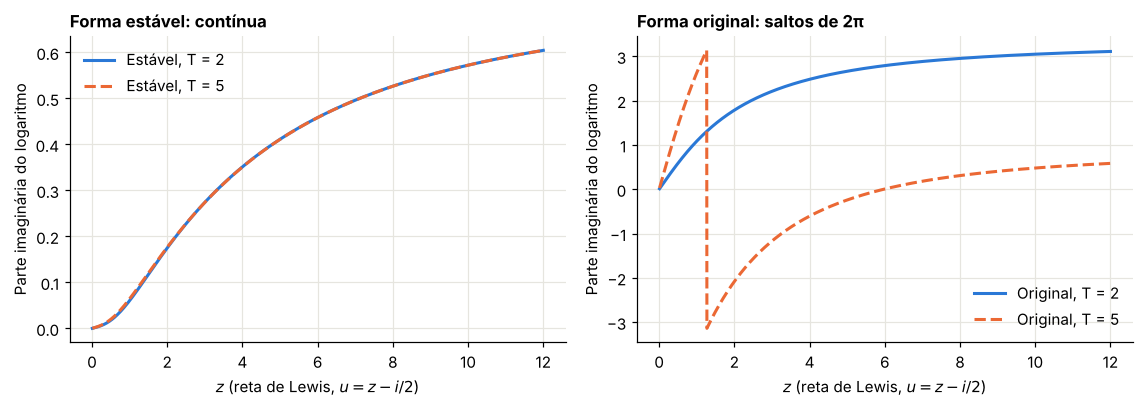

OK — em prazo curto, as duas formas coincidem
OK — em prazo longo, a forma original dá um preço errado


In [3]:
def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Forma estável (Albrecher et al.): a usada pelo livro."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


def cf_heston_original(u, T, v0, kappa, theta, sigma, rho):
    """Forma de Heston (1993), com a outra raiz."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi + d) / (xi - d)
    with np.errstate(all="ignore"):
        e = np.exp(d * T)
        A = kappa * theta / sigma**2 * ((xi + d) * T - 2 * np.log((1 - g * e) / (1 - g)))
        B = (xi + d) / sigma**2 * (1 - e) / (1 - g * e)
        return np.exp(A + B * v0)


def cf_heston_ode(u, T, v0, kappa, theta, sigma, rho):
    xi = kappa - rho * sigma * 1j * u

    def eqs(t, y):
        A, B = y[0] + 1j * y[1], y[2] + 1j * y[3]
        dA = kappa * theta * B
        dB = 0.5 * sigma**2 * B**2 - xi * B - 0.5 * (u**2 + 1j * u)
        return [dA.real, dA.imag, dB.real, dB.imag]

    s = solve_ivp(eqs, (0, T), [0, 0, 0, 0], rtol=1e-10, atol=1e-12, method="DOP853").y[:, -1]
    return np.exp(s[0] + 1j * s[1] + (s[2] + 1j * s[3]) * v0)


H = dict(v0=0.04, kappa=1.0, theta=0.04, sigma=0.9, rho=-0.7)
us = [0.5, 2.0, 7.0, 15.0]
dif = max(abs(cf_heston(u, 2.0, **H) - cf_heston_ode(u, 2.0, **H)) for u in us)
ok(dif < 1e-8, "a fórmula estável resolve as equações de Riccati")
ok(abs(cf_heston(-1j, 3.0, **H) - 1) < 1e-12, "martingale: φ(−i) = 1")

Z = np.linspace(0.0, 200.0, 20001)


def lewis(S, K, T, r, cf):
    K = np.atleast_1d(np.asarray(K, float))
    k = np.log(S / K) + r * T
    h = np.exp(1j * Z * k[:, None]) * cf(Z - 0.5j)
    return S - np.sqrt(S * K) * np.exp(-0.5 * r * T) / np.pi * simpson(h.real / (Z**2 + 0.25), x=Z, axis=1)


S0, r = 100.0, 0.02
linhas = []
for T in [1.0, 2.0, 5.0, 10.0]:
    a = float(lewis(S0, 100.0, T, r, lambda u: cf_heston(u, T, **H))[0])
    b = float(lewis(S0, 100.0, T, r, lambda u: cf_heston_original(u, T, **H))[0])
    linhas.append({"Prazo": T, "Forma estável": a, "Forma original": b})
arm = pd.DataFrame(linhas)
tabela(arm)

ur = np.linspace(0.01, 12, 2000)
xi = H["kappa"] - H["rho"] * H["sigma"] * 1j * (ur - 0.5j)
d = np.sqrt(xi**2 + H["sigma"] ** 2 * (1j * (ur - 0.5j) + (ur - 0.5j) ** 2))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for T, cor, est in [(2.0, AZUL, "-"), (5.0, LARANJA, "--")]:
    g1, g2 = (xi - d) / (xi + d), (xi + d) / (xi - d)
    with np.errstate(all="ignore"):
        a1.plot(ur, np.imag(np.log((1 - g1 * np.exp(-d * T)) / (1 - g1))), color=cor, ls=est, label=f"Estável, T = {T:.0f}")
        a2.plot(ur, np.imag(np.log((1 - g2 * np.exp(d * T)) / (1 - g2))), color=cor, ls=est, label=f"Original, T = {T:.0f}")
for ax, t in [(a1, "Forma estável: contínua"), (a2, "Forma original: saltos de 2π")]:
    ax.set_title(t)
    ax.set_xlabel("$z$ (reta de Lewis, $u = z - i/2$)")
    ax.set_ylabel("Parte imaginária do logaritmo")
    ax.legend()
plt.tight_layout()
plt.show()

ok(abs(arm["Forma estável"].iloc[0] - arm["Forma original"].iloc[0]) < 1e-8, "em prazo curto, as duas formas coincidem")
ok(not np.isclose(arm["Forma estável"].iloc[2], arm["Forma original"].iloc[2], atol=0.01), "em prazo longo, a forma original dá um preço errado")

### Laboratório 3.2 — Conferência por simulação

Uma última conferência, independente das deduções: Monte Carlo com esquema de Euler e truncamento total, em passos finos (o Módulo 12 discute alternativas melhores).

In [4]:
def heston_mc(S0, r, T, v0, kappa, theta, sigma, rho, M, I, rng):
    dt = T / M
    v = np.full(I, v0)
    x = np.zeros(I)
    for _ in range(M):
        z1 = rng.standard_normal(I)
        z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(I)
        vp = np.maximum(v, 0.0)
        x += (r - 0.5 * vp) * dt + np.sqrt(vp * dt) * z1
        v += kappa * (theta - vp) * dt + sigma * np.sqrt(vp * dt) * z2
    return S0 * np.exp(x)


rng = np.random.default_rng(1102)
ST = heston_mc(S0, r, 1.0, **H, M=500, I=200_000, rng=rng)
linhas = []
for K in [80.0, 100.0, 120.0]:
    a = np.exp(-r) * np.maximum(ST - K, 0.0)
    ref = float(lewis(S0, K, 1.0, r, lambda u: cf_heston(u, 1.0, **H))[0])
    linhas.append({"Strike": K, "Lewis": ref, "Monte Carlo": a.mean(), "Erro-padrão": a.std(ddof=1) / np.sqrt(a.size)})
mc = pd.DataFrame(linhas)
tabela(mc)
ok(((mc["Lewis"] - mc["Monte Carlo"]).abs() < 4 * mc["Erro-padrão"] + 0.02).all(), "Monte Carlo confere com a fórmula de Heston")

,Strike,Lewis,Monte Carlo,Erro-padrão
0,"80,000","23,286","23,324","0,027"
1,"100,000","6,924","6,949","0,018"
2,"120,000","0,518","0,521","0,008"


OK — Monte Carlo confere com a fórmula de Heston


---
## 4. Juntando: a função característica do BCC97

**Livro: §9.5.2, equações (9.11) a (9.13)**

Como os saltos são independentes da parte de Heston, a função característica do log-retorno é o produto (Módulo 7):

$$\phi^{BCC97}(u) = \phi^{H93}(u)\cdot\phi^{M76J}(u), \qquad \phi^{M76J}(u) = \exp\Big\{T\Big[-iu\,r_J + \lambda\big(e^{iu\mu_J - u^2\delta^2/2} - 1\big)\Big]\Big\}.$$

Os juros entram, no livro, por um atalho: a taxa constante é substituída pela taxa zero do CIR para o prazo da opção, $\bar r_T = -\ln P(0, T)/T$. A Seção 6 examina esse atalho.

### Laboratório 4.1 — Os casos particulares

In [5]:
def cf_bcc(u, T, v0, kappa, theta, sigma, rho, lam, mu, delta):
    rj = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    saltos = np.exp(T * (-1j * u * rj + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)))
    return cf_heston(u, T, v0, kappa, theta, sigma, rho) * saltos


def merton_serie(S, K, T, r, sig, lam, mu, delta, n_max=60):
    from scipy.stats import poisson
    kap = np.exp(mu + 0.5 * delta**2) - 1
    tot = 0.0
    for n in range(n_max):
        sn = np.sqrt(sig**2 + n * delta**2 / T)
        rn = r - lam * kap + n * np.log1p(kap) / T
        tot = tot + poisson.pmf(n, lam * (1 + kap) * T) * bsm(S, K, T, rn, sn)
    return tot


K = np.array([85.0, 100.0, 115.0])
T = 0.75
eps = 1e-5
bsm_via = lewis(S0, K, T, r, lambda u: cf_bcc(u, T, 0.04, 1.0, 0.04, eps, 0.0, 0.0, 0.0, 0.1))
m76_via = lewis(S0, K, T, r, lambda u: cf_bcc(u, T, 0.03, 1.0, 0.03, eps, 0.0, 0.8, -0.1, 0.08))
h93_via = lewis(S0, K, T, r, lambda u: cf_bcc(u, T, **H, lam=0.0, mu=0.0, delta=0.1))
tabela(pd.DataFrame({"Strike": K, "BCC97 → BSM": bsm_via, "BSM": bsm(S0, K, T, r, 0.2), "BCC97 → M76": m76_via, "Série de Merton": merton_serie(S0, K, T, r, np.sqrt(0.03), 0.8, -0.1, 0.08), "BCC97 → H93": h93_via, "Heston": lewis(S0, K, T, r, lambda u: cf_heston(u, T, **H))}))
ok(np.max(np.abs(bsm_via - bsm(S0, K, T, r, 0.2))) < 1e-4, "com σ_v → 0 e sem saltos, o BCC97 vira BSM")
ok(np.max(np.abs(m76_via - merton_serie(S0, K, T, r, np.sqrt(0.03), 0.8, -0.1, 0.08))) < 1e-4, "com σ_v → 0, vira Merton")
ok(np.max(np.abs(h93_via - lewis(S0, K, T, r, lambda u: cf_heston(u, T, **H)))) < 1e-12, "sem saltos, vira Heston")

,Strike,BCC97 → BSM,BSM,BCC97 → M76,Série de Merton,BCC97 → H93,Heston
0,"85,000","17,522","17,522","17,780","17,780","18,083","18,083"
1,"100,000","7,620","7,620","7,744","7,744","5,964","5,964"
2,"115,000","2,539","2,539","2,465","2,465","0,618","0,618"


OK — com σ_v → 0 e sem saltos, o BCC97 vira BSM
OK — com σ_v → 0, vira Merton
OK — sem saltos, vira Heston


---
## 5. A EDP do modelo

**Livro: §9.5.1 e §9.7.1**

### 5.1 Itô em várias dimensões, com saltos

Para $f(S, v, r, t)$, a expansão de Taylor de segunda ordem com as regras $(dZ^i)^2 = dt$, $dZ^1dZ^2 = \rho\,dt$ e demais produtos nulos dá a parte contínua. O salto exige outro tratamento: num salto, $S$ passa de $S_-$ a $S_-e^J$ de uma vez, e a variação de $f$ é a diferença **exata**, e não uma derivada:

$$df = f_t\,dt + f_S\,dS^c + f_v\,dv + f_r\,dr + \tfrac12\big(vS^2f_{SS} + \sigma_v^2vf_{vv} + \sigma_r^2rf_{rr}\big)dt + \rho\sigma_vvSf_{Sv}\,dt + \big[f(S_-e^J) - f(S_-)\big]dN,$$

em que $dS^c$ é a parte contínua de $dS$.

### 5.2 A EDP

Sob $Q$, o preço descontado de qualquer derivativo é martingale, logo o drift de $dC$ é $rC$. Tomando a esperança dos termos e usando $\mathbb{E}[dN] = \lambda\,dt$:

$$\tfrac12vS^2C_{SS} + (r - r_J)SC_S + \rho\sigma_vvS\,C_{Sv} + \tfrac12\sigma_v^2v\,C_{vv} + \kappa_v(\theta_v - v)C_v$$
$$+\ \tfrac12\sigma_r^2r\,C_{rr} + \kappa_r(\theta_r - r)C_r + C_t - rC + \lambda\,\mathbb{E}\big[C(Se^J) - C(S)\big] = 0.$$

Duas observações:

1. Ao contrário do BSM, essa EDP **não** vem de uma replicação. O mercado é incompleto (Módulo 4), e a equação vale sob a medida $Q$ escolhida. Os parâmetros que aparecem nela são os parâmetros **sob $Q$**, que é o que a calibração estima.
2. Usamos $\mathbb{E}[dN] = \lambda\,dt$, mas o termo $f_S\,dS$ usa só a parte contínua. Se usássemos $f_S\,dS$ completo, o salto seria contado duas vezes.

> **Erratas do livro na equação (9.8).** (i) O primeiro termo aparece como $\tfrac12vS^2\,\partial^2C/\partial S$; o denominador correto é $\partial S^2$. (ii) Faltam os fatores de variância nos termos de difusão de $v$ e $r$: o correto é $\tfrac12\sigma_v^2\,v\,\partial^2C/\partial v^2$ e $\tfrac12\sigma_r^2\,r\,\partial^2C/\partial r^2$, já que os coeficientes de difusão são $\sigma_v\sqrt v$ e $\sigma_r\sqrt r$, cujos quadrados aparecem na própria prova. (iii) Na prova, o termo de salto entra como $\frac{\partial A}{\partial S}\,jdN$, uma aproximação de primeira ordem, enquanto a EDP usa a diferença exata, que é a forma correta.

### Laboratório 5.1 — A fórmula de Fourier satisfaz a EDP?

Com juros constantes, calculamos as derivadas de $C(S, v, \tau)$ por diferenças finitas sobre preços de Lewis, e o termo de salto por quadratura de Gauss-Hermite. O resíduo da EDP correta deve ser próximo de zero. Testamos também a versão impressa, sem o fator $v$ em $C_{vv}$.

In [6]:
B96 = dict(kappa=1.5, theta=0.04, sigma=0.5, rho=-0.7, lam=0.5, mu=-0.10, delta=0.10)


def preco(S, v, tau, K=100.0, r=0.02):
    return float(lewis(S, K, tau, r, lambda u: cf_bcc(u, tau, v, **B96))[0])


def residuos(S, v, tau, r=0.02):
    hS, hv, ht = 0.5, 1e-3, 1e-4
    C = preco(S, v, tau)
    CS = (preco(S + hS, v, tau) - preco(S - hS, v, tau)) / (2 * hS)
    CSS = (preco(S + hS, v, tau) - 2 * C + preco(S - hS, v, tau)) / hS**2
    Cv = (preco(S, v + hv, tau) - preco(S, v - hv, tau)) / (2 * hv)
    Cvv = (preco(S, v + hv, tau) - 2 * C + preco(S, v - hv, tau)) / hv**2
    CSv = (preco(S + hS, v + hv, tau) - preco(S + hS, v - hv, tau) - preco(S - hS, v + hv, tau) + preco(S - hS, v - hv, tau)) / (4 * hS * hv)
    Ct = -(preco(S, v, tau + ht) - preco(S, v, tau - ht)) / (2 * ht)
    x, w = np.polynomial.hermite_e.hermegauss(40)
    w = w / w.sum()
    Jn = B96["mu"] + B96["delta"] * x
    salto = sum(wi * preco(S * np.exp(ji), v, tau) for wi, ji in zip(w, Jn)) - C
    rj = B96["lam"] * (np.exp(B96["mu"] + 0.5 * B96["delta"] ** 2) - 1)
    comum = 0.5 * v * S**2 * CSS + (r - rj) * S * CS + B96["rho"] * B96["sigma"] * v * S * CSv + B96["kappa"] * (B96["theta"] - v) * Cv + Ct - r * C + B96["lam"] * salto
    return comum + 0.5 * B96["sigma"] ** 2 * v * Cvv, comum + 0.5 * B96["sigma"] ** 2 * Cvv, C


linhas = []
for S, v, tau in [(100.0, 0.04, 0.5), (90.0, 0.02, 1.0), (115.0, 0.06, 0.25)]:
    rc, ri, C = residuos(S, v, tau)
    linhas.append({"S": S, "v": v, "τ": tau, "Preço": C, "Resíduo: EDP correta": rc, "Resíduo: sem o fator v em C_vv": ri})
edp = pd.DataFrame(linhas)
tabela(edp)
ok((edp["Resíduo: EDP correta"].abs() < 2e-3).all(), "o preço de Fourier satisfaz a EDP correta")
ok((edp["Resíduo: sem o fator v em C_vv"].abs() > 0.05).all(), "a forma impressa, sem o fator v, não é satisfeita")

,S,v,τ,Preço,Resíduo: EDP correta,Resíduo: sem o fator v em C_vv
0,"100,000","0,040","0,500","6,399","-0,002","-35,060"
1,"90,000","0,020","1,000","2,822","-0,001","-16,669"
2,"115,000","0,060","0,250","16,830","0,000","0,104"


OK — o preço de Fourier satisfaz a EDP correta
OK — a forma impressa, sem o fator v, não é satisfeita


---
## 6. Juros estocásticos: o que o atalho do livro deixa de fora

**Livro: §9.5.2, definição de $r_{0,T}$ em $H_1$**

### 6.1 O preço exato, sob independência

Seja $R = \int_0^T r_s\,ds$. Como os juros são independentes do resto, escrevemos $S_T = S_0\,e^{R}\,X$, em que $X$ depende só da volatilidade e dos saltos. O preço é

$$C_0 = \mathbb{E}\big[e^{-R}(S_0e^{R}X - K)^+\big] = \mathbb{E}_R\Big[\underbrace{\mathbb{E}_X\big[e^{-R}(S_0e^{R}X - K)^+\big]}_{\text{preço com taxa constante } R/T}\Big].$$

O preço exato é a **média**, sobre os cenários de juros, dos preços com taxa constante igual a $R/T$.

### 6.2 O atalho

O livro, seguindo uma prática comum, usa um único valor: $\bar r_T = -\ln P(0,T)/T$. Pela desigualdade de Jensen, $\mathbb{E}[e^{-R}] = P(0,T)$, ou seja, o atalho acerta o desconto médio. Mas o preço da call não é linear em $R$: ele é **convexo**, porque juros mais altos aumentam o forward e o valor da call, com curvatura. A diferença é

$$C^{\text{exato}} - C^{\text{atalho}} = \mathbb{E}_R\big[C(R/T)\big] - C(\bar r_T),$$

pequena quando a variância de $R$ é pequena. O artigo original de Bakshi, Cao e Chen trata isso de forma exata, usando a função característica conjunta com os juros. O atalho é uma simplificação do livro.

### Laboratório 6.1 — O tamanho do efeito

Calculamos o preço exato pela média sobre 400 quantis da distribuição de $R$, simulada pela transição exata do CIR. Variamos o prazo e a volatilidade dos juros.

In [7]:
B97 = dict(v0=0.04, kappa=1.5, theta=0.04, sigma=0.5, rho=-0.7, lam=0.5, mu=-0.10, delta=0.10)


def preco_taxa(K, T, rbar):
    """Preço com taxa constante rbar, vetorizado em rbar."""
    rbar = np.atleast_1d(rbar)
    fi = cf_bcc(Z - 0.5j, T, **B97)
    k = np.log(S0 / K) + rbar[:, None] * T
    integ = simpson((np.exp(1j * Z * k) * fi).real / (Z**2 + 0.25), x=Z, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * rbar * T) / np.pi * integ


rng = np.random.default_rng(1103)
linhas = []
for sig_r in [0.05, 0.12, 0.25]:
    cir = dict(r0=0.02, kappa=0.8, theta=0.035, sigma=sig_r)
    for T in [0.5, 2.0, 5.0]:
        R_ = simular_cir(**cir, T=T, M=int(50 * T), I=100_000, rng=rng)
        q = np.quantile(R_, (np.arange(400) + 0.5) / 400)
        rbar = -np.log(zero_cir(T, **cir)) / T
        for K in [100.0]:
            exato = float(np.mean(preco_taxa(K, T, q / T)))
            atalho = float(preco_taxa(K, T, rbar)[0])
            linhas.append({"σ_r": sig_r, "Prazo": T, "Desvio de R/T (p.p.)": float(np.std(R_ / T) * 100), "Exato": exato, "Atalho do livro": atalho, "Diferença": exato - atalho, "Diferença (% do preço)": (exato - atalho) / exato * 100})
jur = pd.DataFrame(linhas)
tabela(jur)
ok((jur["Diferença"] > -1e-3).all(), "o atalho nunca supera o preço exato: efeito de convexidade")
ok(jur.query("σ_r == 0.12 and Prazo == 0.5")["Diferença (% do preço)"].iloc[0] < 0.1, "com volatilidade de juros moderada e prazo curto, o atalho é excelente")
ok(jur["Diferença (% do preço)"].max() > 5 * jur.query("σ_r == 0.12 and Prazo == 0.5")["Diferença (% do preço)"].iloc[0], "o erro do atalho cresce com o prazo e com a volatilidade dos juros")

,σ_r,Prazo,Desvio de R/T (p.p.),Exato,Atalho do livro,Diferença,Diferença (% do preço)
0,"0,050","0,500","0,259","6,477","6,476","0,000","0,007"
1,"0,050","2,000","0,388","14,346","14,343","0,003","0,023"
2,"0,050","5,000","0,384","25,779","25,770","0,010","0,037"
3,"0,120","0,500","0,622","6,478","6,476","0,001","0,021"
4,"0,120","2,000","0,926","14,352","14,335","0,017","0,118"
5,"0,120","5,000","0,925","25,789","25,726","0,063","0,245"
6,"0,250","0,500","1,293","6,480","6,475","0,005","0,075"
7,"0,250","2,000","1,933","14,389","14,304","0,085","0,593"
8,"0,250","5,000","1,926","25,810","25,556","0,253","0,982"


OK — o atalho nunca supera o preço exato: efeito de convexidade
OK — com volatilidade de juros moderada e prazo curto, o atalho é excelente
OK — o erro do atalho cresce com o prazo e com a volatilidade dos juros


**Leitura.** Para os prazos das opções listadas de índice, de dias a poucos meses, o atalho é praticamente exato. Para produtos longos ou híbridos, que dependem de juros e ações ao mesmo tempo, é preciso o tratamento completo, que também abriria espaço para correlação entre juros e índice, ausente no BCC97.

---
## 7. O que cada parâmetro faz com a superfície

Antes de calibrar (Módulos 13 e 14), vale ter intuição sobre o papel de cada parâmetro. Variamos um parâmetro de cada vez a partir de um caso-base e olhamos para a volatilidade implícita em dois prazos.

### Laboratório 7.1 — Os parâmetros, um a um

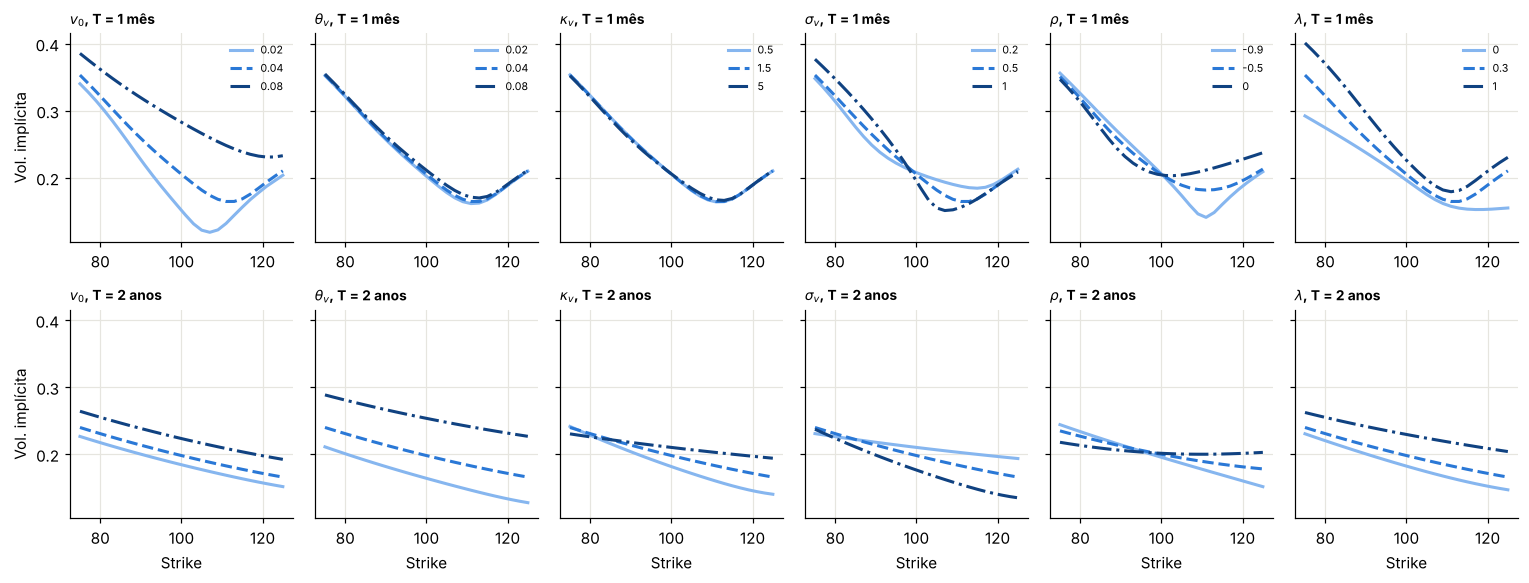

,Parâmetro,Prazo,Variação do nível,Variação do skew
0,v0,1 mês,"0,088","0,007"
1,v0,2 anos,"0,039","-0,003"
2,theta,1 mês,"0,006","0,001"
3,theta,2 anos,"0,089","-0,019"
4,kappa,1 mês,"-0,000","-0,002"
5,kappa,2 anos,"0,026","-0,056"
6,sigma,1 mês,"0,004","0,038"
7,sigma,2 anos,"-0,031","0,056"
8,rho,1 mês,"0,012","-0,051"
9,rho,2 anos,"0,008","-0,065"


OK — v0 domina o nível dos prazos curtos
OK — θ domina o nível dos prazos longos
OK — ρ mais alto (menos negativo) reduz o skew
OK — os saltos pesam mais no skew dos prazos curtos


In [8]:
base = dict(v0=0.04, kappa=1.5, theta=0.04, sigma=0.5, rho=-0.7, lam=0.3, mu=-0.10, delta=0.10)
variacoes = {
    "v0": [0.02, 0.04, 0.08],
    "theta": [0.02, 0.04, 0.08],
    "kappa": [0.5, 1.5, 5.0],
    "sigma": [0.2, 0.5, 1.0],
    "rho": [-0.9, -0.5, 0.0],
    "lam": [0.0, 0.3, 1.0],
}
nomes = {"v0": "$v_0$", "theta": "$\\theta_v$", "kappa": "$\\kappa_v$", "sigma": "$\\sigma_v$", "rho": "$\\rho$", "lam": "$\\lambda$"}
Ks = np.linspace(75, 125, 26)
fig, eixos = plt.subplots(2, 6, figsize=(14, 5.4), sharey=True)
efeito = {}
for j, (par, vals) in enumerate(variacoes.items()):
    for i, T in enumerate([1 / 12, 2.0]):
        ax = eixos[i, j]
        niveis = []
        for v_, cor, est in zip(vals, RAMPA, ["-", "--", "-."]):
            p = {**base, par: v_}
            c = lewis(S0, Ks, T, 0.02, lambda u: cf_bcc(u, T, **p))
            iv = np.array([vol_impl(cc, S0, k, T, 0.02) for cc, k in zip(c, Ks)])
            ax.plot(Ks, iv, color=cor, ls=est, label=f"{v_:g}")
            niveis.append(iv)
        efeito[(par, T)] = (np.nanmean(niveis[-1] - niveis[0]), np.nanmean((niveis[-1][:5] - niveis[-1][-5:]) - (niveis[0][:5] - niveis[0][-5:])))
        ax.set_title(f"{nomes[par]}, T = {'1 mês' if T < 1 else '2 anos'}", fontsize=9)
        if i == 1:
            ax.set_xlabel("Strike")
        if j == 0:
            ax.set_ylabel("Vol. implícita")
        if i == 0:
            ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

ef = pd.DataFrame([{"Parâmetro": p, "Prazo": "1 mês" if T < 1 else "2 anos", "Variação do nível": n, "Variação do skew": s} for (p, T), (n, s) in efeito.items()])
tabela(ef)
e = {(r_["Parâmetro"], r_["Prazo"]): r_ for _, r_ in ef.iterrows()}
ok(abs(e[("v0", "1 mês")]["Variação do nível"]) > 2 * abs(e[("v0", "2 anos")]["Variação do nível"]), "v0 domina o nível dos prazos curtos")
ok(abs(e[("theta", "2 anos")]["Variação do nível"]) > 2 * abs(e[("theta", "1 mês")]["Variação do nível"]), "θ domina o nível dos prazos longos")
ok(e[("rho", "2 anos")]["Variação do skew"] < 0, "ρ mais alto (menos negativo) reduz o skew")
ok(e[("lam", "1 mês")]["Variação do skew"] > e[("lam", "2 anos")]["Variação do skew"], "os saltos pesam mais no skew dos prazos curtos")

**Resumo para a calibração:**

| Parâmetro | Efeito principal |
|---|---|
| $v_0$ | nível dos prazos curtos |
| $\theta_v$ | nível dos prazos longos |
| $\kappa_v$ | velocidade de passagem de $v_0$ para $\theta_v$ ao longo dos prazos |
| $\sigma_v$ | curvatura do smile |
| $\rho$ | inclinação (skew) |
| $\lambda, \mu_J, \delta$ | skew e caudas dos prazos curtos |

Vários parâmetros têm efeitos parecidos. Isso antecipa o que veremos na calibração: algumas combinações são bem determinadas pelo mercado, outras não.

---
## 8. Síntese

- O BCC97 junta Bates (índice) e CIR (juros), e contém BSM, Merton e Heston como casos particulares.
- A estrutura afim transforma o problema de preço em equações de Riccati, tanto nos juros quanto na volatilidade.
- A fórmula de Heston tem duas formas equivalentes na matemática; só a estável funciona no computador.
- A EDP vale sob $Q$, sem replicação, e o salto entra por diferença exata.
- O atalho do livro para juros estocásticos é excelente em prazos curtos e se degrada nos longos.
- Cada parâmetro tem uma assinatura na superfície, com sobreposições.

## 9. Notas sobre o livro neste capítulo

| Local | Comentário |
|---|---|
| §9.2 | a lei do salto não corresponde a $r_J$ nem a (9.11); o correto é $J \sim N(\mu_J, \delta^2)$ para o log-salto |
| Eq. (9.8) | $\partial^2C/\partial S$ deveria ser $\partial^2C/\partial S^2$ |
| Eq. (9.8) | faltam os fatores $v$ e $r$ nos termos $\tfrac12\sigma_v^2\,\partial^2C/\partial v^2$ e $\tfrac12\sigma_r^2\,\partial^2C/\partial r^2$ |
| Prova da Prop. 8 | o salto entra como $\partial A/\partial S\cdot jdN$, aproximação de primeira ordem; o certo é a diferença exata, como a própria (9.8) usa |
| Prova da Prop. 8 | na primeira linha da expansão, $\partial A/\partial t$ aparece dentro do fator $\tfrac12$ |
| §9.5.2 | o uso de $r_{0,T} = -\ln B_0(T)/T$ é uma aproximação, não o tratamento de juros estocásticos do artigo original |
| Eq. (9.10) | a forma usada é a estável, com $c_2 = -d$; ponto positivo do livro |

## 10. Exercícios

**Exercício 1.** Verifique que $b(\tau)$ do CIR satisfaz $b'(0) = 1$ e interprete.

<details><summary>Solução</summary>

Pela equação, $b'(0) = 1 - 0 - 0 = 1$. Para prazos curtos, $b(\tau) \approx \tau$ e $P \approx e^{-r\tau}$: no curto prazo, o desconto é pela taxa atual.
</details>

**Exercício 2.** Use a Riccati de Heston para mostrar que, com $\sigma_v = 0$ e $v_0 = \theta_v$, a função característica é a do BSM.

<details><summary>Solução</summary>

Com $\sigma_v = 0$: $B' = -\kappa_vB - \tfrac12(u^2 + iu)$, linear. Com $v_0 = \theta_v$, a variância fica constante, e $A + Bv_0 = -\tfrac12\theta_v(u^2 + iu)\tau$, a função característica do BSM com $\sigma^2 = \theta_v$.
</details>

**Exercício 3.** Mostre que $\mathbb{E}[v_T] = \theta_v + (v_0 - \theta_v)e^{-\kappa_vT}$ e use o resultado para explicar a tabela da Seção 7.

<details><summary>Solução</summary>

Tomando esperança em $dv$: $\frac{d}{dt}\mathbb{E}[v] = \kappa_v(\theta_v - \mathbb{E}[v])$, cuja solução é a dada. A variância média até $T$ é uma média ponderada entre $v_0$ e $\theta_v$, com mais peso em $v_0$ para prazos curtos.
</details>

**Exercício 4.** Por que a convexidade da Seção 6 tem o sinal que tem? E para uma put?

<details><summary>Solução</summary>

Como função de $\bar r$, a call é $S_0 - \dots$; seu preço cresce e é convexo em $\bar r$, e a média de uma função convexa supera a função da média. Para a put, que cai com $\bar r$, a convexidade também vale; por paridade, $P = C - S_0 + K e^{-\bar rT}$, e $Ke^{-\bar rT}$ também é convexo.
</details>

In [9]:
print(f"Módulo 11 concluído: {_checks['n']} verificações aprovadas.")

Módulo 11 concluído: 19 verificações aprovadas.
